# 03 - Previous Applications EDA

Exploratory analysis of `previous_application.csv`: previous Home Credit applications linked to the current application by `SK_ID_CURR` and identified by `SK_ID_PREV`.

## Purpose

This notebook answers previous-application questions before feature engineering. It checks the table grain and joins, application outcomes, product/channel structure, amount relationships, temporal fields, and potential leakage-sensitive columns.

**Context:** [00_dataset_overview.ipynb](00_dataset_overview.ipynb) | [01_application_eda.ipynb](01_application_eda.ipynb) | [02_bureau_eda.ipynb](02_bureau_eda.ipynb) | [docs/glossary.md](../../docs/glossary.md) | `data/HomeCredit_columns_description.csv`

## Out of scope

- Credit scoring model training
- Null-importance feature selection
- Fairness metrics / mitigation


## 0. Load and shape

Load `previous_application.csv` and the application ID/target columns needed for coverage checks. This section records table size, memory use, grain, and join keys.


In [1]:
from pathlib import Path
import os

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 100)

HIGH_MISSINGNESS_THRESHOLD = 0.50
PREVIOUS_KEYS = ["SK_ID_CURR", "SK_ID_PREV"]
UNREALIZED_DATE_SENTINEL = 365243

_cwd = Path.cwd()
if not (_cwd / "data" / "previous_application.csv").exists():
    repo_root = (_cwd / "../..").resolve()
    if (repo_root / "data" / "previous_application.csv").exists():
        os.chdir(repo_root)
    else:
        raise FileNotFoundError(
            "Place Home Credit CSVs in data/ and run with repo root or analysis/notebooks/ as cwd."
        )

DATA_DIR = Path("data")


def load_csv(path: Path, **kwargs) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")
    return pd.read_csv(path, **kwargs)


previous = load_csv(DATA_DIR / "previous_application.csv")
app_train = load_csv(DATA_DIR / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"])
app_test = load_csv(DATA_DIR / "application_test.csv", usecols=["SK_ID_CURR"])

shape_summary = pd.DataFrame(
    [
        {
            "table": "previous_application",
            "rows": len(previous),
            "columns": previous.shape[1],
            "keys": ", ".join(PREVIOUS_KEYS),
            "grain": "One row per previous Home Credit application",
        }
    ]
)
display(shape_summary.style.hide(axis="index"))


table,rows,columns,keys,grain
previous_application,1670214,37,"SK_ID_CURR, SK_ID_PREV",One row per previous Home Credit application


## 1. Schema & missingness

Inspect dtypes, count missing values, and connect columns to the official Home Credit descriptions. High-missing columns are flagged once here and reused later by interpretation, not recomputed in later cells.


In [3]:
def schema_summary(df: pd.DataFrame, table_name: str) -> pd.DataFrame:
    n = len(df)
    rows = []
    for col in df.columns:
        missing = int(df[col].isna().sum())
        n_unique = int(df[col].nunique(dropna=True))
        rows.append(
            {
                "table": table_name,
                "column": col,
                "dtype": str(df[col].dtype),
                "missing_count": missing,
                "%missing": round(100 * missing / n, 2) if n else 0.0,
                "n_unique": n_unique,
                "%unique": round(100 * n_unique / n, 2) if n else 0.0,
            }
        )
    return pd.DataFrame(rows)


schema = schema_summary(previous, "previous_application")

missing_threshold_pct = HIGH_MISSINGNESS_THRESHOLD * 100
high_missing = schema[schema["%missing"] > missing_threshold_pct].sort_values(
    "%missing", ascending=False
)

schema_display_cols = [
    "table",
    "column",
    "dtype",
    "missing_count",
    "%missing",
    "n_unique",
    "%unique",
]

display(Markdown("**Schema with missingness and descriptions**"))
display(
    schema[schema_display_cols]
    .style.hide(axis="index")
    .format({"%missing": "{:.2f}", "%unique": "{:.2f}"})
)

display(Markdown(f"**Columns with >{missing_threshold_pct:.0f}% missing**"))
display(
    high_missing[["column", "dtype", "missing_count", "%missing"]]
    .style.hide(axis="index")
    .format({"%missing": "{:.2f}"})
)


**Schema with missingness and descriptions**

table,column,dtype,missing_count,%missing,n_unique,%unique
previous_application,SK_ID_PREV,int64,0,0.00,1670214,100.00
previous_application,SK_ID_CURR,int64,0,0.00,338857,20.29
previous_application,NAME_CONTRACT_TYPE,str,0,0.00,4,0.00
previous_application,AMT_ANNUITY,float64,372235,22.29,357959,21.43
previous_application,AMT_APPLICATION,float64,0,0.00,93885,5.62
previous_application,AMT_CREDIT,float64,1,0.00,86803,5.20
previous_application,AMT_DOWN_PAYMENT,float64,895844,53.64,29278,1.75
previous_application,AMT_GOODS_PRICE,float64,385515,23.08,93885,5.62
previous_application,WEEKDAY_APPR_PROCESS_START,str,0,0.00,7,0.00
previous_application,HOUR_APPR_PROCESS_START,int64,0,0.00,24,0.00


**Columns with >50% missing**

column,dtype,missing_count,%missing
RATE_INTEREST_PRIVILEGED,float64,1664263,99.64
RATE_INTEREST_PRIMARY,float64,1664263,99.64
RATE_DOWN_PAYMENT,float64,895844,53.64
AMT_DOWN_PAYMENT,float64,895844,53.64


The main high-missing fields are normalized interest-rate fields and down-payment fields. These should not be filled blindly in FE because missingness is tied to product type and application outcome.


## 2. Key integrity and coverage

Check whether IDs are complete and whether `SK_ID_PREV` uniquely identifies one previous application. Then measure how many train/test clients have previous Home Credit application history.


In [3]:
key_integrity = pd.DataFrame(
    [
        {
            "check": "null SK_ID_CURR",
            "value": int(previous["SK_ID_CURR"].isna().sum()),
        },
        {
            "check": "null SK_ID_PREV",
            "value": int(previous["SK_ID_PREV"].isna().sum()),
        },
        {
            "check": "duplicate SK_ID_PREV",
            "value": int(previous["SK_ID_PREV"].duplicated().sum()),
        },
        {
            "check": "duplicate SK_ID_CURR + SK_ID_PREV",
            "value": int(previous.duplicated(PREVIOUS_KEYS).sum()),
        },
        {
            "check": "unique clients in previous_application",
            "value": int(previous["SK_ID_CURR"].nunique()),
        },
    ]
)
display(Markdown("**Key integrity**"))
display(key_integrity.style.hide(axis="index"))

train_ids = set(app_train["SK_ID_CURR"])
test_ids = set(app_test["SK_ID_CURR"])
previous_client_ids = set(previous["SK_ID_CURR"])

coverage = pd.DataFrame(
    [
        {
            "split": "train",
            "clients": len(train_ids),
            "clients_with_previous_app": len(train_ids & previous_client_ids),
            "coverage_pct": round(100 * len(train_ids & previous_client_ids) / len(train_ids), 2),
        },
        {
            "split": "test",
            "clients": len(test_ids),
            "clients_with_previous_app": len(test_ids & previous_client_ids),
            "coverage_pct": round(100 * len(test_ids & previous_client_ids) / len(test_ids), 2),
        },
        {
            "split": "outside_train_test",
            "clients": len(previous_client_ids - train_ids - test_ids),
            "clients_with_previous_app": np.nan,
            "coverage_pct": np.nan,
        },
    ]
)
display(Markdown("**Application coverage by previous-application history**"))
display(coverage.style.hide(axis="index").format({"coverage_pct": "{:.2f}"}))

previous_apps_per_client = previous.groupby("SK_ID_CURR").size()
display(Markdown("**Previous applications per client**"))
display(previous_apps_per_client.describe().rename("previous_apps_per_client").to_frame().T.round(2))

has_previous = app_train["SK_ID_CURR"].isin(previous_client_ids)
default_by_previous_history = pd.DataFrame(
    {
        "group": ["has_previous_app", "no_previous_app"],
        "n_clients": [int(has_previous.sum()), int((~has_previous).sum())],
        "default_rate_pct": [
            round(100 * app_train.loc[has_previous, "TARGET"].mean(), 2),
            round(100 * app_train.loc[~has_previous, "TARGET"].mean(), 2),
        ],
    }
)
display(Markdown("**Train default rate by previous-application presence**"))
display(default_by_previous_history.style.hide(axis="index"))


**Key integrity**

check,value
null SK_ID_CURR,0
null SK_ID_PREV,0
duplicate SK_ID_PREV,0
duplicate SK_ID_CURR + SK_ID_PREV,0
unique clients in previous_application,338857


**Application coverage by previous-application history**

split,clients,clients_with_previous_app,coverage_pct
train,307511,291057.000000,94.65
test,48744,47800.000000,98.06
outside_train_test,0,nan,nan


**Previous applications per client**

,count,mean,std,min,25%,50%,75%,max
previous_apps_per_client,338857.0,4.93,4.22,1.0,2.0,4.0,7.0,77.0


**Train default rate by previous-application presence**

group,n_clients,default_rate_pct
has_previous_app,291057,8.190000
no_previous_app,16454,5.960000


`SK_ID_PREV` is the unique previous-application row ID, while `SK_ID_CURR` repeats by design because one current applicant can have many previous applications. Previous-application coverage is very high in both train and test, so this table should provide broad feature coverage after aggregation to `SK_ID_CURR`.


## 3. Cardinality and numeric summaries

Summarize categorical variety and numeric ranges. This gives a compact view of product/outcome categories, amount scales, and temporal fields before more focused analysis.


In [4]:
cat_cols = previous.select_dtypes(include=["object", "string"]).columns.tolist()
cat_cardinality = (
    previous[cat_cols]
    .nunique(dropna=True)
    .sort_values(ascending=False)
    .rename("unique_categories")
    .reset_index()
    .rename(columns={"index": "column"})
)
display(Markdown("**Categorical cardinality**"))
display(cat_cardinality.style.hide(axis="index"))

xna_counts = []
for col in cat_cols:
    n_xna = int((previous[col] == "XNA").sum())
    if n_xna:
        xna_counts.append(
            {
                "column": col,
                "XNA_count": n_xna,
                "XNA_pct": round(100 * n_xna / len(previous), 2),
            }
        )
xna_summary = pd.DataFrame(xna_counts).sort_values("XNA_pct", ascending=False)
display(Markdown("**Categorical columns with XNA labels**"))
display(xna_summary.style.hide(axis="index").format({"XNA_pct": "{:.2f}"}))

selected_categoricals = [
    "NAME_CONTRACT_STATUS",
    "NAME_CONTRACT_TYPE",
    "NAME_CLIENT_TYPE",
    "NAME_PORTFOLIO",
    "NAME_PRODUCT_TYPE",
    "CHANNEL_TYPE",
    "NAME_YIELD_GROUP",
    "PRODUCT_COMBINATION",
]
for col in selected_categoricals:
    counts = previous[col].value_counts(dropna=False).head(12).rename("count").reset_index()
    counts.columns = [col, "count"]
    counts["pct"] = (100 * counts["count"] / len(previous)).round(2)
    display(Markdown(f"**Top values: `{col}`**"))
    display(counts.style.hide(axis="index").format({"pct": "{:.2f}"}))


**Categorical cardinality**

column,unique_categories
NAME_GOODS_CATEGORY,28
NAME_CASH_LOAN_PURPOSE,25
PRODUCT_COMBINATION,17
NAME_SELLER_INDUSTRY,11
CODE_REJECT_REASON,9
CHANNEL_TYPE,8
NAME_TYPE_SUITE,7
WEEKDAY_APPR_PROCESS_START,7
NAME_PORTFOLIO,5
NAME_YIELD_GROUP,5


**Categorical columns with XNA labels**

column,XNA_count,XNA_pct
NAME_PRODUCT_TYPE,1063666,63.68
NAME_GOODS_CATEGORY,950809,56.93
NAME_SELLER_INDUSTRY,855720,51.23
NAME_CASH_LOAN_PURPOSE,677918,40.59
NAME_PAYMENT_TYPE,627384,37.56
NAME_YIELD_GROUP,517215,30.97
NAME_PORTFOLIO,372230,22.29
CODE_REJECT_REASON,5244,0.31
NAME_CLIENT_TYPE,1941,0.12
NAME_CONTRACT_TYPE,346,0.02


**Top values: `NAME_CONTRACT_STATUS`**

...

CHANNEL_TYPE,count,pct
Credit and cash offices,719968,43.11
Country-wide,494690,29.62
Stone,212083,12.70
Regional / Local,108528,6.50
Contact center,71297,4.27
AP+ (Cash loan),57046,3.42
Channel of corporate sales,6150,0.37
Car dealer,452,0.03


**Top values: `NAME_YIELD_GROUP`**

NAME_YIELD_GROUP,count,pct
XNA,517215,30.97
middle,385532,23.08
high,353331,21.15
low_normal,322095,19.28
low_action,92041,5.51


**Top values: `PRODUCT_COMBINATION`**

PRODUCT_COMBINATION,count,pct
Cash,285990,17.12
POS household with interest,263622,15.78
POS mobile with interest,220670,13.21
Cash X-Sell: middle,143883,8.61
Cash X-Sell: low,130248,7.80
Card Street,112582,6.74
POS industry with interest,98833,5.92
POS household without interest,82908,4.96
Card X-Sell,80582,4.82
Cash Street: high,59639,3.57


Several categorical fields use `XNA` as a structural placeholder rather than a true category, especially product/purpose fields. Keep `XNA` distinct from `NaN` during EDA; Later I should decide whether it should remain as its own category or become a missing/unknown indicator.


In [5]:
numeric_cols = [c for c in previous.select_dtypes(include=[np.number]).columns if c not in PREVIOUS_KEYS]
numeric_summary = previous[numeric_cols].describe().T
numeric_summary["missing_pct"] = (100 * previous[numeric_cols].isna().mean()).round(2)

display(Markdown("**Numeric summary**"))
display(numeric_summary.round(2))


**Numeric summary**

,count,mean,std,min,25%,50%,75%,max,missing_pct
AMT_ANNUITY,1297979.0,15955.12,14782.14,0.00,6321.78,11250.00,20658.42,418058.14,22.29
AMT_APPLICATION,1670214.0,175233.86,292779.76,0.00,18720.00,71046.00,180360.00,6905160.00,0.00
AMT_CREDIT,1670213.0,196114.02,318574.62,0.00,24160.50,80541.00,216418.50,6905160.00,0.00
AMT_DOWN_PAYMENT,774370.0,6697.40,20921.50,-0.90,0.00,1638.00,7740.00,3060045.00,53.64
AMT_GOODS_PRICE,1284699.0,227847.28,315396.56,0.00,50841.00,112320.00,234000.00,6905160.00,23.08
HOUR_APPR_PROCESS_START,1670214.0,12.48,3.33,0.00,10.00,12.00,15.00,23.00,0.00
NFLAG_LAST_APPL_IN_DAY,1670214.0,1.00,0.06,0.00,1.00,1.00,1.00,1.00,0.00
RATE_DOWN_PAYMENT,774370.0,0.08,0.11,-0.00,0.00,0.05,0.11,1.00,53.64
RATE_INTEREST_PRIMARY,5951.0,0.19,0.09,0.03,0.16,0.19,0.19,1.00,99.64
RATE_INTEREST_PRIVILEGED,5951.0,0.77,0.10,0.37,0.72,0.84,0.85,1.00,99.64


Amount columns are highly skewed and some fields have structural zeros. `SELLERPLACE_AREA` includes many `-1` values and one very large maximum, so it should be treated as a coded/dirty operational field rather than a clean geographic area.


## 4. Contract outcomes and rejection reasons

Look at previous application decisions and why applications were rejected. This is useful for credit scoring model training, but status-like fields should be reviewed for leakage risk because they summarize a previous application outcome.


In [6]:
status_counts = previous["NAME_CONTRACT_STATUS"].value_counts(dropna=False).rename("count").reset_index()
status_counts.columns = ["NAME_CONTRACT_STATUS", "count"]
status_counts["pct"] = (100 * status_counts["count"] / len(previous)).round(2)
display(Markdown("**Previous application outcomes**"))
display(status_counts.style.hide(axis="index").format({"pct": "{:.2f}"}))

status_by_type = pd.crosstab(
    previous["NAME_CONTRACT_TYPE"],
    previous["NAME_CONTRACT_STATUS"],
    normalize="index",
).mul(100).round(2)
display(Markdown("**Outcome mix by contract type (% within contract type)**"))
display(status_by_type)

refused = previous[previous["NAME_CONTRACT_STATUS"] == "Refused"]
reject_reasons = refused["CODE_REJECT_REASON"].value_counts(dropna=False).rename("count").reset_index()
reject_reasons.columns = ["CODE_REJECT_REASON", "count"]
reject_reasons["pct_of_refused"] = (100 * reject_reasons["count"] / len(refused)).round(2)
display(Markdown("**Reject reasons among refused previous applications**"))
display(reject_reasons.style.hide(axis="index").format({"pct_of_refused": "{:.2f}"}))


**Previous application outcomes**

NAME_CONTRACT_STATUS,count,pct
Approved,1036781,62.07
Canceled,316319,18.94
Refused,290678,17.40
Unused offer,26436,1.58


**Outcome mix by contract type (% within contract type)**

NAME_CONTRACT_STATUS,Approved,Canceled,Refused,Unused offer
NAME_CONTRACT_TYPE,,,,
Cash loans,41.81,35.93,22.20,0.07
Consumer loans,85.92,0.21,10.31,3.56
Revolving loans,50.62,23.74,25.64,0.00
XNA,0.00,91.04,8.96,0.00


**Reject reasons among refused previous applications**

CODE_REJECT_REASON,count,pct_of_refused
HC,175231,60.28
LIMIT,55680,19.16
SCO,37467,12.89
SCOFR,12811,4.41
XNA,5236,1.80
VERIF,3535,1.22
SYSTEM,717,0.25
XAP,1,0.00


Most previous applications are approved, but cancelled and refused applications are also substantial groups. `CODE_REJECT_REASON` is meaningful mainly for refused applications; `XAP` often marks not-applicable cases rather than an actual reject reason.


## 5. Amounts, products, and channels

Inspect requested amount vs final credit amount, zero-amount applications, down-payment fields, and sales/product channels.


In [7]:
amount_cols = [
    "AMT_APPLICATION",
    "AMT_CREDIT",
    "AMT_GOODS_PRICE",
    "AMT_DOWN_PAYMENT",
    "AMT_ANNUITY",
    "CNT_PAYMENT",
]
amount_summary = previous[amount_cols].describe().T.round(2)
display(Markdown("**Amount and payment-term summary**"))
display(amount_summary)

amount_relationship = previous[["AMT_APPLICATION", "AMT_CREDIT", "AMT_GOODS_PRICE", "AMT_DOWN_PAYMENT"]].copy()
amount_relationship["credit_minus_application"] = (
    amount_relationship["AMT_CREDIT"] - amount_relationship["AMT_APPLICATION"]
)
amount_quality = pd.DataFrame(
    [
        {
            "check": "AMT_APPLICATION == 0",
            "n_rows": int((previous["AMT_APPLICATION"] == 0).sum()),
            "pct_rows": round(100 * (previous["AMT_APPLICATION"] == 0).mean(), 2),
        },
        {
            "check": "AMT_CREDIT < AMT_APPLICATION",
            "n_rows": int((amount_relationship["credit_minus_application"] < 0).sum()),
            "pct_rows": round(100 * (amount_relationship["credit_minus_application"] < 0).mean(), 2),
        },
        {
            "check": "AMT_DOWN_PAYMENT < 0",
            "n_rows": int((previous["AMT_DOWN_PAYMENT"] < 0).sum()),
            "pct_rows": round(100 * (previous["AMT_DOWN_PAYMENT"] < 0).mean(), 4),
        },
        {
            "check": "SELLERPLACE_AREA == -1",
            "n_rows": int((previous["SELLERPLACE_AREA"] == -1).sum()),
            "pct_rows": round(100 * (previous["SELLERPLACE_AREA"] == -1).mean(), 2),
        },
    ]
)
display(Markdown("**Amount and seller-place data quality checks**"))
display(amount_quality.style.hide(axis="index"))

display(Markdown("**Credit minus application amount**"))
display(amount_relationship["credit_minus_application"].describe().round(2).to_frame().T)

channel_product = pd.crosstab(
    previous["CHANNEL_TYPE"],
    previous["NAME_CONTRACT_TYPE"],
    normalize="index",
).mul(100).round(2)
display(Markdown("**Contract type mix by channel (% within channel)**"))
display(channel_product)


**Amount and payment-term summary**

,count,mean,std,min,25%,50%,75%,max
AMT_APPLICATION,1670214.0,175233.86,292779.76,0.0,18720.00,71046.0,180360.00,6905160.00
AMT_CREDIT,1670213.0,196114.02,318574.62,0.0,24160.50,80541.0,216418.50,6905160.00
AMT_GOODS_PRICE,1284699.0,227847.28,315396.56,0.0,50841.00,112320.0,234000.00,6905160.00
AMT_DOWN_PAYMENT,774370.0,6697.40,20921.50,-0.9,0.00,1638.0,7740.00,3060045.00
AMT_ANNUITY,1297979.0,15955.12,14782.14,0.0,6321.78,11250.0,20658.42,418058.14
CNT_PAYMENT,1297984.0,16.05,14.57,0.0,6.00,12.0,24.00,84.00


**Amount and seller-place data quality checks**

check,n_rows,pct_rows
AMT_APPLICATION == 0,392402,23.490000
AMT_CREDIT < AMT_APPLICATION,357691,21.420000
AMT_DOWN_PAYMENT < 0,2,0.000100
SELLERPLACE_AREA == -1,762675,45.660000


**Credit minus application amount**

,count,mean,std,min,25%,50%,75%,max
credit_minus_application,1670213.0,20880.06,71939.08,-3020449.5,0.0,0.0,12919.5,1350000.0


**Contract type mix by channel (% within channel)**

NAME_CONTRACT_TYPE,Cash loans,Consumer loans,Revolving loans,XNA
CHANNEL_TYPE,,,,
AP+ (Cash loan),71.65,0.05,28.30,0.00
Car dealer,5.97,93.58,0.44,0.00
Channel of corporate sales,77.33,0.00,22.67,0.00
Contact center,84.14,0.00,15.86,0.00
Country-wide,8.54,85.98,5.41,0.07
Credit and cash offices,82.39,0.13,17.47,0.00
Regional / Local,2.78,91.76,5.46,0.00
Stone,1.62,95.63,2.74,0.00


The requested amount and final credit amount often differ, which matches the data dictionary. Zero application amounts and `SELLERPLACE_AREA == -1` are common enough to require explicit handling before aggregation.


## 6. Temporal fields and sentinels

Check how far back previous decisions occurred and whether day columns contain the Home Credit sentinel `365243`. These columns are relative to the current application date.


In [8]:
day_cols = [c for c in previous.columns if c.startswith("DAYS_")]

day_summary = previous[day_cols].describe().T.round(2)
display(Markdown("**Day-field summary**"))
display(day_summary)

sentinel_rows = []
for col in day_cols:
    sentinel_count = int((previous[col] == UNREALIZED_DATE_SENTINEL).sum())
    sentinel_rows.append(
        {
            "column": col,
            "sentinel_count": sentinel_count,
            "sentinel_pct": round(100 * sentinel_count / len(previous), 2),
            "missing_pct": round(100 * previous[col].isna().mean(), 2),
            "min": previous[col].min(),
            "max": previous[col].max(),
        }
    )
sentinel_summary = pd.DataFrame(sentinel_rows).sort_values("sentinel_pct", ascending=False)
display(Markdown(f"**`{UNREALIZED_DATE_SENTINEL}` sentinel in day columns**"))
display(sentinel_summary.style.hide(axis="index"))

latest_decision_by_client = previous.groupby("SK_ID_CURR")["DAYS_DECISION"].max()
display(Markdown("**Most recent previous-application decision per client**"))
display(latest_decision_by_client.describe().rename("latest_days_decision").to_frame().T.round(2))


**Day-field summary**

,count,mean,std,min,25%,50%,75%,max
DAYS_DECISION,1670214.0,-880.68,779.10,-2922.0,-1300.0,-581.0,-280.0,-1.0
DAYS_FIRST_DRAWING,997149.0,342209.86,88916.12,-2922.0,365243.0,365243.0,365243.0,365243.0
DAYS_FIRST_DUE,997149.0,13826.27,72444.87,-2892.0,-1628.0,-831.0,-411.0,365243.0
DAYS_LAST_DUE_1ST_VERSION,997149.0,33767.77,106857.03,-2801.0,-1242.0,-361.0,129.0,365243.0
DAYS_LAST_DUE,997149.0,76582.40,149647.42,-2889.0,-1314.0,-537.0,-74.0,365243.0
DAYS_TERMINATION,997149.0,81992.34,153303.52,-2874.0,-1270.0,-499.0,-44.0,365243.0


**`365243` sentinel in day columns**

column,sentinel_count,sentinel_pct,missing_pct,min,max
DAYS_FIRST_DRAWING,934444,55.950000,40.300000,-2922.000000,365243.000000
DAYS_TERMINATION,225913,13.530000,40.300000,-2874.000000,365243.000000
DAYS_LAST_DUE,211221,12.650000,40.300000,-2889.000000,365243.000000
DAYS_LAST_DUE_1ST_VERSION,93864,5.620000,40.300000,-2801.000000,365243.000000
DAYS_FIRST_DUE,40645,2.430000,40.300000,-2892.000000,365243.000000
DAYS_DECISION,0,0.000000,0.000000,-2922.000000,-1.000000


**Most recent previous-application decision per client**

,count,mean,std,min,25%,50%,75%,max
latest_days_decision,338857.0,-481.49,536.93,-2922.0,-596.0,-304.0,-151.0,-1.0


`DAYS_DECISION` is always negative, so decisions happened before the current application. Several post-approval schedule fields contain `365243`, which should be treated as a sentinel for unrealized or not-applicable dates rather than a real future date.


## 7. Repeated applications, last-application flags, and insurance

Inspect fields that describe repeated applications and insurance-on-approval. These are useful for the model, but some are only meaningful for applications that reached approval.


In [9]:
flag_cols = [
    "FLAG_LAST_APPL_PER_CONTRACT",
    "NFLAG_LAST_APPL_IN_DAY",
    "NFLAG_INSURED_ON_APPROVAL",
]
for col in flag_cols:
    counts = previous[col].value_counts(dropna=False).rename("count").reset_index()
    counts.columns = [col, "count"]
    counts["pct"] = (100 * counts["count"] / len(previous)).round(2)
    display(Markdown(f"**Value counts: `{col}`**"))
    display(counts.style.hide(axis="index").format({"pct": "{:.2f}"}))

same_day_apps = previous.groupby(["SK_ID_CURR", "DAYS_DECISION"]).size().rename("apps_same_day")
same_day_summary = same_day_apps.describe().rename("apps_per_client_decision_day").to_frame().T

display(Markdown("**Applications per client per decision day**"))
display(same_day_summary.round(2))

approval_insurance = (
    previous[previous["NAME_CONTRACT_STATUS"] == "Approved"]
    .groupby("NFLAG_INSURED_ON_APPROVAL", dropna=False)
    .size()
    .rename("count")
    .reset_index()
)
approval_insurance["pct_of_approved"] = (100 * approval_insurance["count"] / approval_insurance["count"].sum()).round(2)
display(Markdown("**Insurance flag among approved previous applications**"))
display(approval_insurance.style.hide(axis="index"))


**Value counts: `FLAG_LAST_APPL_PER_CONTRACT`**

FLAG_LAST_APPL_PER_CONTRACT,count,pct
Y,1661739,99.49
N,8475,0.51


**Value counts: `NFLAG_LAST_APPL_IN_DAY`**

NFLAG_LAST_APPL_IN_DAY,count,pct
1,1664314,99.65
0,5900,0.35


**Value counts: `NFLAG_INSURED_ON_APPROVAL`**

NFLAG_INSURED_ON_APPROVAL,count,pct
nan,673065,40.30
0.000000,665527,39.85
1.000000,331622,19.86


**Applications per client per decision day**

,count,mean,std,min,25%,50%,75%,max
apps_per_client_decision_day,1321915.0,1.26,0.74,1.0,1.0,1.0,1.0,49.0


**Insurance flag among approved previous applications**

NFLAG_INSURED_ON_APPROVAL,count,pct_of_approved
0.000000,665527,64.190000
1.000000,331622,31.990000
nan,39632,3.820000


The last-application flags help identify repeated or superseded applications. `NFLAG_INSURED_ON_APPROVAL` has structural missingness because it only applies after approval-like workflows, so FE should combine it with approval status or an availability flag.


## 8. Plots

Visualize the main distributions: application outcomes, previous applications per client, and recency of previous decisions.


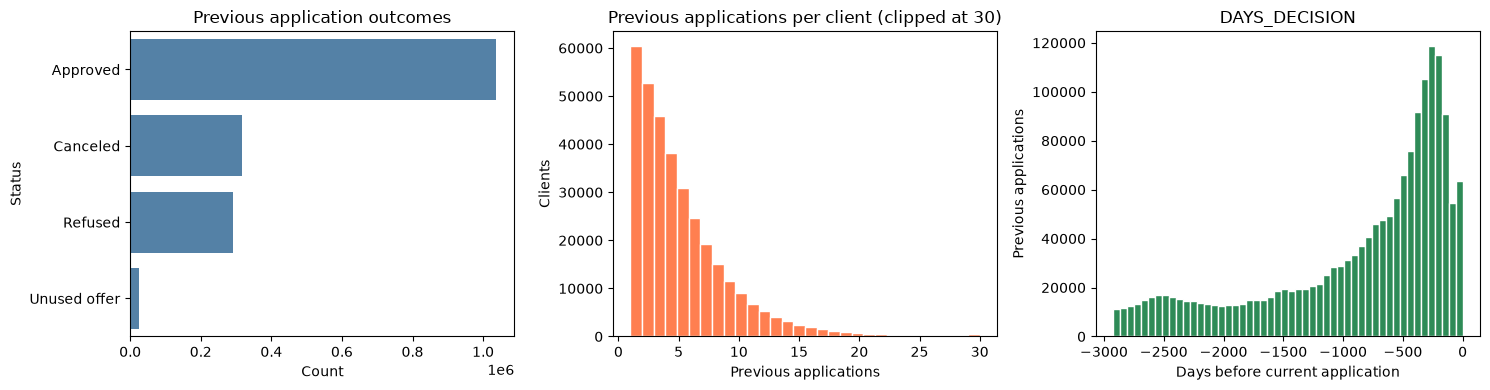

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

status_order = previous["NAME_CONTRACT_STATUS"].value_counts().index
sns.countplot(data=previous, y="NAME_CONTRACT_STATUS", order=status_order, ax=axes[0], color="steelblue")
axes[0].set_title("Previous application outcomes")
axes[0].set_xlabel("Count")
axes[0].set_ylabel("Status")

previous_apps_per_client = previous.groupby("SK_ID_CURR").size()
axes[1].hist(previous_apps_per_client.clip(upper=30), bins=30, color="coral", edgecolor="white")
axes[1].set_title("Previous applications per client (clipped at 30)")
axes[1].set_xlabel("Previous applications")
axes[1].set_ylabel("Clients")

axes[2].hist(previous["DAYS_DECISION"], bins=50, color="seagreen", edgecolor="white")
axes[2].set_title("DAYS_DECISION")
axes[2].set_xlabel("Days before current application")
axes[2].set_ylabel("Previous applications")

plt.tight_layout()
plt.show()


## 9. FE / join / leakage / fairness notes

Preview client-level aggregates and document what should be handled later in feature engineering. This section does not train a model or select features.


In [11]:
previous_fe_preview = (
    previous.assign(
        is_approved=previous["NAME_CONTRACT_STATUS"].eq("Approved"),
        is_refused=previous["NAME_CONTRACT_STATUS"].eq("Refused"),
        has_unrealized_schedule=previous[day_cols].eq(UNREALIZED_DATE_SENTINEL).any(axis=1),
    )
    .groupby("SK_ID_CURR")
    .agg(
        previous_app_count=("SK_ID_PREV", "count"),
        previous_approved_count=("is_approved", "sum"),
        previous_refused_count=("is_refused", "sum"),
        latest_previous_decision_days=("DAYS_DECISION", "max"),
        mean_previous_credit=("AMT_CREDIT", "mean"),
        max_previous_credit=("AMT_CREDIT", "max"),
        has_unrealized_previous_schedule=("has_unrealized_schedule", "max"),
    )
    .reset_index()
)

display(Markdown("**Example client-level previous-application aggregates (preview only)**"))
display(previous_fe_preview.head(5).style.hide(axis="index"))


**Example client-level previous-application aggregates (preview only)**

SK_ID_CURR,previous_app_count,previous_approved_count,previous_refused_count,latest_previous_decision_days,mean_previous_credit,max_previous_credit,has_unrealized_previous_schedule
100001,1,1,0,-1740,23787.000000,23787.000000,True
100002,1,1,0,-606,179055.000000,179055.000000,True
100003,3,3,0,-746,484191.000000,1035882.000000,True
100004,1,1,0,-815,20106.000000,20106.000000,True
100005,2,1,0,-315,20076.750000,40153.500000,True


**Join path for FE:** aggregate `previous_application` directly to `SK_ID_CURR`, and use `SK_ID_PREV` later to connect installments, POS/cash, and credit-card history.

**Leakage caution:** previous application outcomes are historical relative to the current application and are plausible bureau-style risk signals, but reject reasons, approval status, insurance-on-approval, and post-approval schedule fields should be reviewed carefully before modeling. The `365243` day sentinel must be converted to missing/indicator form, not treated as a true date.

**Fairness / proxy note:** this table has no protected attributes, but product type, channel, seller industry, rejection reason, and insurance uptake may correlate with socioeconomic status. Keep them available for later audit in `07_protected_attributes.ipynb`.


## Summary of findings

_Executed successfully on 2026-07-16._

- **Grain / keys:** `previous_application` has 1,670,214 rows x 37 columns. `SK_ID_PREV` is unique, and both `SK_ID_CURR` / `SK_ID_PREV` have no nulls.
- **Coverage:** Previous Home Credit application history covers ~94.7% of train clients and ~98.1% of test clients. Clients with previous history have a higher raw train default rate (~8.2%) than clients without it (~6.0%); this is descriptive only.
- **Applications per client:** Clients with previous history have a mean of ~4.9 previous applications, median 4, and max 77. FE should aggregate by `SK_ID_CURR`.
- **Missingness:** Four columns exceed 50% missing: `RATE_INTEREST_PRIVILEGED` and `RATE_INTEREST_PRIMARY` (~99.6%), plus `AMT_DOWN_PAYMENT` and `RATE_DOWN_PAYMENT` (~53.6%). Several post-approval date/insurance fields are ~40.3% missing.
- **Outcomes:** Previous applications are mostly Approved (~62.1%), with substantial Canceled (~18.9%) and Refused (~17.4%) groups. Reject reasons are meaningful mainly for refused rows; `XAP` is mostly not-applicable.
- **Products and amounts:** Cash loans and Consumer loans dominate. `AMT_CREDIT` differs from `AMT_APPLICATION` by design; in ~21.4% of rows final credit is below requested amount. `AMT_APPLICATION == 0` appears in ~23.5% of rows.
- **Operational anomalies:** `SELLERPLACE_AREA == -1` is common (~45.7%) and the max is very large, so treat it as a coded/dirty operational feature. Several categorical columns use `XNA` as a structural placeholder.
- **Temporal fields:** `DAYS_DECISION` ranges from -2922 to -1, so previous decisions occur before the current application. Post-approval schedule columns often contain sentinel `365243`, especially `DAYS_FIRST_DRAWING` (~56.0% of rows); convert this to missing/indicator form in FE.
- **FE / leakage / fairness notes:** Aggregate directly to `SK_ID_CURR`; keep `SK_ID_PREV` for linking installments, POS/cash, and credit-card history. Outcome/reject/approval fields are historical but target-like, so review temporal meaning before modeling. Product, channel, seller industry, rejection reason, and insurance uptake may act as socioeconomic proxies and should be audited later.
